## BOM

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")

# If the notebook is inside notebooks/
if not DATA_DIR.exists():
    DATA_DIR = Path("../data")

bom_raw = pd.read_csv(DATA_DIR / "bom_materials.csv")

bom_raw

,product_ref,plant_code,plant_name,material_label_source,material_family,share_pct,mass_kg,eu_series_ids,ww_series_ids,comment
0,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Carbon Steel EU (CR coil),Carbon steel,0.520,327.2,L01;S09,S04;S12,NaN
1,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Stainless Steel EU 304L,Stainless steel,0.163,102.6,L02;S09,S03,NaN
2,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,PBT Polybutylene terephthalate EU,Engineering plastic,0.022,13.8,L04;S11,S13,NaN
3,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Not categorized ETP EU,Engineering plastic,0.018,11.3,L06;S11,S13,"ETP = engineering thermoplastics, grade unknown"
4,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Aluminium /ton,Aluminium,0.008,5.0,D02;S08;L07,S02,NaN
5,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Other,Other,0.136,85.6,NaN,NaN,Not priceable – composition unknown
6,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,"Unlabelled slices (orange ~8%, light blue, teal)",To confirm,NaN,NaN,NaN,NaN,Labels not visible in chart – check source BOM
7,RM6_NE_IQI_433520,ETO_FR0900,SFCME,"Unlabelled largest slice (blue, ~45%)",Carbon steel (to confirm),NaN,NaN,L01;S09,S04;S12,Most likely Carbon Steel EU (CR coil) – confir...
8,RM6_NE_IQI_433520,ETO_FR0900,SFCME,Stainless Steel EU 304L,Stainless steel,0.180,55.8,L02;S09,S03,NaN
9,RM6_NE_IQI_433520,ETO_FR0900,SFCME,Copper /ton,Copper,0.125,38.8,D01;S07;L08,S01,NaN


### Data Cleaning

In [3]:
# Data Cleaning
bom = bom_raw.dropna(subset=["material_family"]).copy()

bom["product"] = bom["product_ref"].map({
    "RM6_NE_IQI_433520": "RM6",
    "RMAirSeT IIQ 24kV IEC": "RM AirSeT"
})

bom = bom.reset_index(drop=True)

bom.head()

,product_ref,plant_code,plant_name,material_label_source,material_family,share_pct,mass_kg,eu_series_ids,ww_series_ids,comment,product
0,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Carbon Steel EU (CR coil),Carbon steel,0.520,327.2,L01;S09,S04;S12,NaN,RM AirSeT
1,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Stainless Steel EU 304L,Stainless steel,0.163,102.6,L02;S09,S03,NaN,RM AirSeT
2,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,PBT Polybutylene terephthalate EU,Engineering plastic,0.022,13.8,L04;S11,S13,NaN,RM AirSeT
3,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Not categorized ETP EU,Engineering plastic,0.018,11.3,L06;S11,S13,"ETP = engineering thermoplastics, grade unknown",RM AirSeT
4,RMAirSeT IIQ 24kV IEC,ETO_HU1100,Duna Smart Power Systems,Aluminium /ton,Aluminium,0.008,5.0,D02;S08;L07,S02,NaN,RM AirSeT


### Missing Value

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": bom.isna().sum(),
    "missing_pct": bom.isna().mean() * 100
})

missing_summary.round(2)

,missing_count,missing_pct
product_ref,0,0.00
plant_code,0,0.00
plant_name,0,0.00
material_label_source,0,0.00
material_family,0,0.00
share_pct,3,21.43
mass_kg,3,21.43
eu_series_ids,3,21.43
ww_series_ids,3,21.43
comment,9,64.29


In [7]:
missing_bom = bom.loc[
    bom["mass_kg"].isna() | bom["share_pct"].isna() | bom["eu_series_ids"].isna() | bom["ww_series_ids"].isna(),
    [
        "product",
        "material_label_source",
        "material_family",
        "share_pct",
        "mass_kg",
        "eu_series_ids",
        "ww_series_ids",
        "comment"
    ]
]

missing_bom

,product,material_label_source,material_family,share_pct,mass_kg,eu_series_ids,ww_series_ids,comment
5,RM AirSeT,Other,Other,0.136,85.6,NaN,NaN,Not priceable – composition unknown
6,RM AirSeT,"Unlabelled slices (orange ~8%, light blue, teal)",To confirm,NaN,NaN,NaN,NaN,Labels not visible in chart – check source BOM
7,RM6,"Unlabelled largest slice (blue, ~45%)",Carbon steel (to confirm),NaN,NaN,L01;S09,S04;S12,Most likely Carbon Steel EU (CR coil) – confir...
13,RM6,"Small unlabelled slices (pink, brown, teal…)",To confirm,NaN,NaN,NaN,NaN,Labels not visible in chart


### Material Composition Analysis

In [8]:
material_mass = bom.pivot_table(
    index="material_family",
    columns="product",
    values="mass_kg",
    aggfunc="sum",
    min_count=1
)

In [9]:
material_mass = (
    bom.groupby(["material_family", "product"])["mass_kg"]
    .sum(min_count=1)
    .unstack()
)

material_mass

product,RM AirSeT,RM6
material_family,,
Aluminium,5.0,5.0
Carbon steel,327.2,NaN
Carbon steel (to confirm),NaN,NaN
Copper,NaN,38.8
Engineering plastic,25.1,NaN
Galvanised steel,NaN,21.1
Other,85.6,NaN
Plastic,NaN,5.6
Stainless steel,102.6,55.8


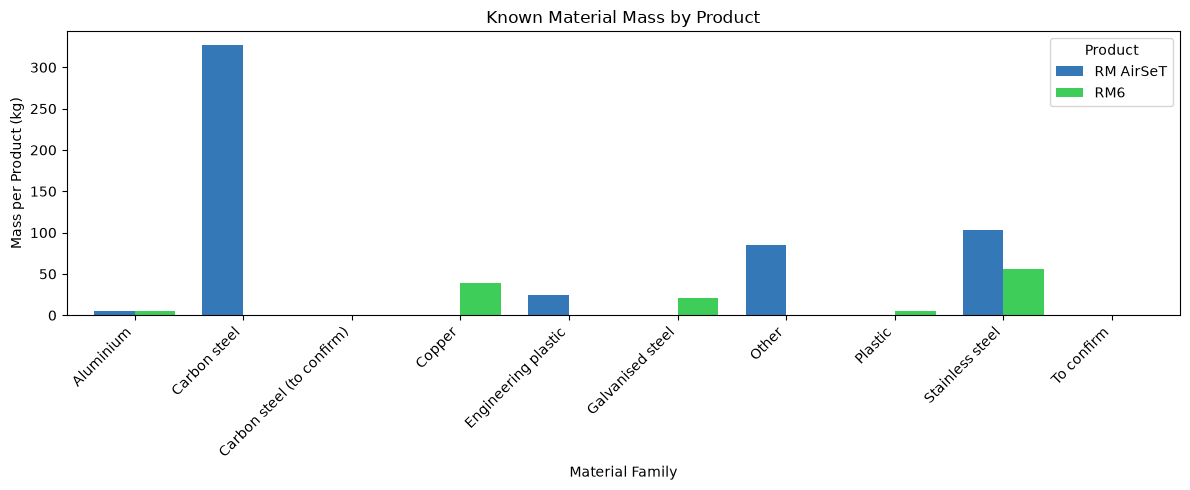

In [10]:
material_mass.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.75,
    color=["#3478B8", "#3DCD58"]
)

plt.title("Known Material Mass by Product")
plt.xlabel("Material Family")
plt.ylabel("Mass per Product (kg)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Product")
plt.tight_layout()
plt.show()

### BOM Data Coverage Analysis

In [12]:
rm_prices = pd.read_csv(
    DATA_DIR / "rm_prices_monthly_wide.csv"
)

available_series = set(
    rm_prices.drop(
        columns=["month", "year", "month_num"]
    )
    .dropna(axis=1, how="all")
    .columns
)

available_series

{'D01',
 'D02',
 'S01',
 'S02',
 'S03',
 'S04',
 'S05',
 'S06',
 'S07',
 'S08',
 'S09',
 'S10',
 'S11',
 'S12',
 'S13'}

In [13]:
def has_available_price(series_ids):
    if pd.isna(series_ids):
        return False

    ids = series_ids.split(";")

    return any(
        series_id in available_series
        for series_id in ids
    )


bom["has_price_proxy"] = (
    bom["eu_series_ids"].apply(has_available_price)
)

bom[[
    "product",
    "material_family",
    "share_pct",
    "eu_series_ids",
    "has_price_proxy"
]]

,product,material_family,share_pct,eu_series_ids,has_price_proxy
0,RM AirSeT,Carbon steel,0.520,L01;S09,True
1,RM AirSeT,Stainless steel,0.163,L02;S09,True
2,RM AirSeT,Engineering plastic,0.022,L04;S11,True
3,RM AirSeT,Engineering plastic,0.018,L06;S11,True
4,RM AirSeT,Aluminium,0.008,D02;S08;L07,True
5,RM AirSeT,Other,0.136,NaN,False
6,RM AirSeT,To confirm,NaN,NaN,False
7,RM6,Carbon steel (to confirm),NaN,L01;S09,True
8,RM6,Stainless steel,0.180,L02;S09,True
9,RM6,Copper,0.125,D01;S07;L08,True


#### Calculate confirmed coverage

In [15]:
confirmed_coverage = (
    bom.loc[bom["has_price_proxy"]]
    .groupby("product")["share_pct"]
    .sum()
)

confirmed_coverage

product
RM AirSeT    0.731
RM6          0.407
Name: share_pct, dtype: float64

#### Build coverage summary

In [16]:
coverage = pd.DataFrame(
    index=["RM6", "RM AirSeT"]
)

coverage["Confirmed & price proxy available"] = (
    confirmed_coverage
)

# Assumption from the original BOM annotation
coverage["Carbon steel to confirm"] = [0.45, 0.0]

coverage["Unknown / not priceable"] = (
    1 - coverage.sum(axis=1)
)

coverage_pct = coverage * 100

coverage_pct.round(1)

,Confirmed & price proxy available,Carbon steel to confirm,Unknown / not priceable
RM6,40.7,45.0,14.3
RM AirSeT,73.1,0.0,26.9


#### Visualize BOM coverage

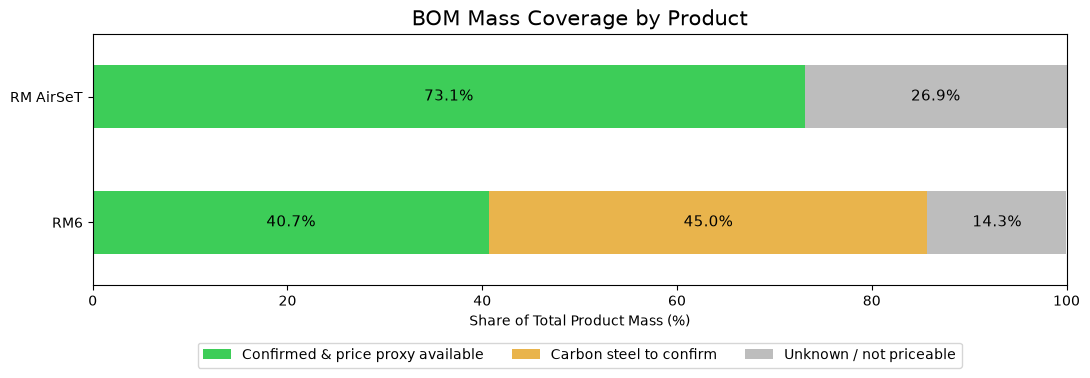

In [18]:
ax = coverage_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 4),
    color=["#3DCD58", "#E9B44C", "#BDBDBD"],
    width=0.5
)

for container in ax.containers:
    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=11
    )

ax.set_title("BOM Mass Coverage by Product", fontsize=15)
ax.set_xlabel("Share of Total Product Mass (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3
)

plt.tight_layout()
plt.show()

### Price Mapping

#### Price Data Availability

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "data/RM_Prices_XHEC_Challenge.xlsx"

catalog = pd.read_excel(
    file_path, sheet_name="Source_Catalog"
)

prices = pd.read_excel(
    file_path, sheet_name="Monthly_Wide"
)

bom = pd.read_csv("data/bom_materials.csv")

# Remove summary rows
bom = bom[bom["material_family"].notna()].copy()

catalog.head()

,series_id,material,region,series_name,provider,provider_code,unit,currency,frequency,access,proxy_type,url,notes
0,S01,Copper,WW,"Copper, grade A cathode, LME – global price",IMF Primary Commodity Prices via FRED,PCOPPUSDM,USD/t,USD,M,Free,Direct,https://fred.stlouisfed.org/series/PCOPPUSDM,Monthly average
1,S02,Aluminium,WW,"Aluminium 99.5% min, LME – global price",IMF Primary Commodity Prices via FRED,PALUMUSDM,USD/t,USD,M,Free,Direct,https://fred.stlouisfed.org/series/PALUMUSDM,Monthly average
2,S03,Nickel,WW,"Nickel, LME – global price",IMF Primary Commodity Prices via FRED,PNICKUSDM,USD/t,USD,M,Free,Driver,https://fred.stlouisfed.org/series/PNICKUSDM,Main cost driver of 304L (≈8-10% Ni)
3,S04,Iron ore,WW,Iron ore fines 62% Fe CFR China,IMF Primary Commodity Prices via FRED,PIORECRUSDM,USD/dmt,USD,M,Free,Driver,https://fred.stlouisfed.org/series/PIORECRUSDM,Main cost driver of carbon steel
4,S05,Zinc,WW,"Zinc, LME – global price",IMF Primary Commodity Prices via FRED,PZINCUSDM,USD/t,USD,M,Free,Driver,https://fred.stlouisfed.org/series/PZINCUSDM,Coating cost driver of HDG


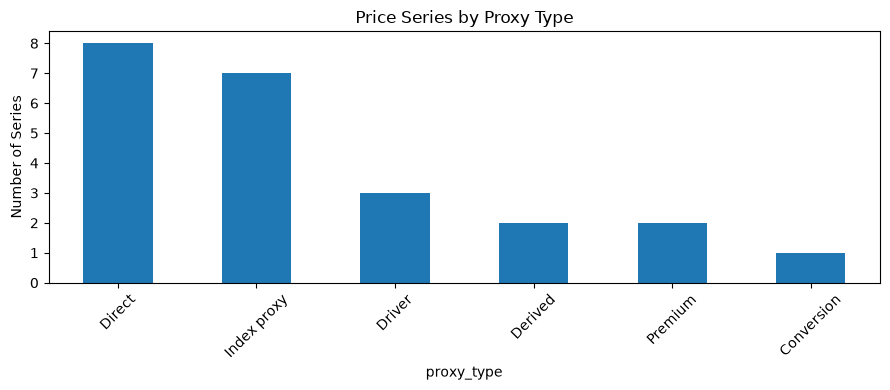

In [23]:
catalog["proxy_type"].value_counts().plot(
    kind="bar",
    figsize=(9, 4),
    title="Price Series by Proxy Type",
    rot=45
)

plt.ylabel("Number of Series")
plt.tight_layout()
plt.show()

In [24]:
series_ids = catalog["series_id"].tolist()

price_availability = pd.DataFrame({
    "series_id": series_ids,
    "n_available": prices[series_ids].notna().sum().values,
    "n_missing": prices[series_ids].isna().sum().values
})

price_availability["coverage"] = (
    price_availability["n_available"] / len(prices)
)

price_availability["has_data"] = (
    price_availability["n_available"] > 0
)

price_availability

,series_id,n_available,n_missing,coverage,has_data
0,S01,119,1,0.991667,True
1,S02,119,1,0.991667,True
2,S03,119,1,0.991667,True
3,S04,119,1,0.991667,True
4,S05,119,1,0.991667,True
5,S06,120,0,1.000000,True
6,S07,119,1,0.991667,True
7,S08,119,1,0.991667,True
8,S09,119,1,0.991667,True
9,S10,119,1,0.991667,True


In [25]:
catalog = catalog.merge(
    price_availability,
    on="series_id",
    how="left",
    validate="one_to_one"
)

catalog[[
    "series_id",
    "material",
    "proxy_type",
    "access",
    "n_available",
    "coverage",
    "has_data"
]]

,series_id,material,proxy_type,access,n_available,coverage,has_data
0,S01,Copper,Direct,Free,119,0.991667,True
1,S02,Aluminium,Direct,Free,119,0.991667,True
2,S03,Nickel,Driver,Free,119,0.991667,True
3,S04,Iron ore,Driver,Free,119,0.991667,True
4,S05,Zinc,Driver,Free,119,0.991667,True
5,S06,FX,Conversion,Free,120,1.000000,True
6,S07,Copper,Index proxy,Free,119,0.991667,True
7,S08,Aluminium,Index proxy,Free,119,0.991667,True
8,S09,Carbon / stainless steel,Index proxy,Free,119,0.991667,True
9,S10,Galvanised steel,Index proxy,Free,119,0.991667,True


#### Series Mapping

In [26]:
mapping = bom.melt(
    id_vars=[
        "product_ref",
        "material_label_source",
        "material_family",
        "share_pct",
        "mass_kg"
    ],
    value_vars=[
        "eu_series_ids",
        "ww_series_ids"
    ],
    var_name="mapping_region",
    value_name="series_id"
)

mapping["mapping_region"] = mapping["mapping_region"].map({
    "eu_series_ids": "EU",
    "ww_series_ids": "WW"
})

# Split multiple series IDs
mapping["series_id"] = mapping["series_id"].str.split(";")

# Expand each series ID into an individual row
mapping = mapping.explode("series_id")

mapping["series_id"] = mapping["series_id"].str.strip()

mapping = mapping.reset_index(drop=True)

mapping.head(10)

,product_ref,material_label_source,material_family,share_pct,mass_kg,mapping_region,series_id
0,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,0.520,327.2,EU,L01
1,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,0.520,327.2,EU,S09
2,RMAirSeT IIQ 24kV IEC,Stainless Steel EU 304L,Stainless steel,0.163,102.6,EU,L02
3,RMAirSeT IIQ 24kV IEC,Stainless Steel EU 304L,Stainless steel,0.163,102.6,EU,S09
4,RMAirSeT IIQ 24kV IEC,PBT Polybutylene terephthalate EU,Engineering plastic,0.022,13.8,EU,L04
5,RMAirSeT IIQ 24kV IEC,PBT Polybutylene terephthalate EU,Engineering plastic,0.022,13.8,EU,S11
6,RMAirSeT IIQ 24kV IEC,Not categorized ETP EU,Engineering plastic,0.018,11.3,EU,L06
7,RMAirSeT IIQ 24kV IEC,Not categorized ETP EU,Engineering plastic,0.018,11.3,EU,S11
8,RMAirSeT IIQ 24kV IEC,Aluminium /ton,Aluminium,0.008,5.0,EU,D02
9,RMAirSeT IIQ 24kV IEC,Aluminium /ton,Aluminium,0.008,5.0,EU,S08


#### Mapping status

In [29]:
mapping = mapping.merge(
    catalog,
    on="series_id",
    how="left",
    validate="many_to_one"
)

mapping.head()

,product_ref,material_label_source,material_family,share_pct,mass_kg,mapping_region,series_id,material,region,series_name,...,currency,frequency,access,proxy_type,url,notes,n_available,n_missing,coverage,has_data
0,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,0.520,327.2,EU,L01,Carbon steel,EU,Cold-rolled coil (CRC) ex-works N. Europe,...,EUR,M,Licensed,Direct,NaN,Check licence before sharing with students,0.0,120.0,0.000000,False
1,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,0.520,327.2,EU,S09,Carbon / stainless steel,EU,Producer price index – Basic iron & steel and ...,...,NaN,M,Free,Index proxy,https://ec.europa.eu/eurostat/databrowser/view...,Covers flat carbon & stainless products,119.0,1.0,0.991667,True
2,RMAirSeT IIQ 24kV IEC,Stainless Steel EU 304L,Stainless steel,0.163,102.6,EU,L02,Stainless steel,EU,"304L cold-rolled 2B sheet, Europe (base + allo...",...,EUR,M,Licensed,Direct,https://www.outokumpu.com/en/surcharges,Alloy surcharge alone is free but is not the f...,0.0,120.0,0.000000,False
3,RMAirSeT IIQ 24kV IEC,Stainless Steel EU 304L,Stainless steel,0.163,102.6,EU,S09,Carbon / stainless steel,EU,Producer price index – Basic iron & steel and ...,...,NaN,M,Free,Index proxy,https://ec.europa.eu/eurostat/databrowser/view...,Covers flat carbon & stainless products,119.0,1.0,0.991667,True
4,RMAirSeT IIQ 24kV IEC,PBT Polybutylene terephthalate EU,Engineering plastic,0.022,13.8,EU,L04,PBT,EU,"PBT unfilled, contract price NW Europe",...,EUR,M,Licensed,Direct,NaN,NaN,0.0,120.0,0.000000,False


In [30]:
mapping_result = mapping[[
    "product_ref",
    "material_label_source",
    "material_family",
    "mapping_region",
    "series_id",
    "series_name",
    "unit",
    "currency",
    "proxy_type",
    "access",
    "coverage",
    "has_data"
]]

mapping_result

,product_ref,material_label_source,material_family,mapping_region,series_id,series_name,unit,currency,proxy_type,access,coverage,has_data
0,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,EU,L01,Cold-rolled coil (CRC) ex-works N. Europe,EUR/t,EUR,Direct,Licensed,0.000000,False
1,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,EU,S09,Producer price index – Basic iron & steel and ...,Index 2021=100,NaN,Index proxy,Free,0.991667,True
2,RMAirSeT IIQ 24kV IEC,Stainless Steel EU 304L,Stainless steel,EU,L02,"304L cold-rolled 2B sheet, Europe (base + allo...",EUR/t,EUR,Direct,Licensed,0.000000,False
3,RMAirSeT IIQ 24kV IEC,Stainless Steel EU 304L,Stainless steel,EU,S09,Producer price index – Basic iron & steel and ...,Index 2021=100,NaN,Index proxy,Free,0.991667,True
4,RMAirSeT IIQ 24kV IEC,PBT Polybutylene terephthalate EU,Engineering plastic,EU,L04,"PBT unfilled, contract price NW Europe",EUR/t,EUR,Direct,Licensed,0.000000,False
5,RMAirSeT IIQ 24kV IEC,PBT Polybutylene terephthalate EU,Engineering plastic,EU,S11,Producer price index – Plastics in primary for...,Index 2021=100,NaN,Index proxy,Free,0.991667,True
6,RMAirSeT IIQ 24kV IEC,Not categorized ETP EU,Engineering plastic,EU,L06,Engineering thermoplastics basket (PA6/PA66/PC...,EUR/t,EUR,Direct,Licensed,0.000000,False
7,RMAirSeT IIQ 24kV IEC,Not categorized ETP EU,Engineering plastic,EU,S11,Producer price index – Plastics in primary for...,Index 2021=100,NaN,Index proxy,Free,0.991667,True
8,RMAirSeT IIQ 24kV IEC,Aluminium /ton,Aluminium,EU,D02,Aluminium LME converted to EUR,EUR/t,EUR,Derived,Free,0.991667,True
9,RMAirSeT IIQ 24kV IEC,Aluminium /ton,Aluminium,EU,S08,Producer price index – Aluminium production (N...,Index 2021=100,NaN,Index proxy,Free,0.991667,True


In [31]:
mapping["mapping_status"] = np.select(
    [
        mapping["series_id"].isna(),
        mapping["series_name"].isna(),
        mapping["has_data"].eq(True)
    ],
    [
        "No mapping",
        "Unknown series",
        "Available"
    ],
    default="Mapped but unavailable"
)

mapping["mapping_status"].value_counts()

mapping_status
Available                 29
Mapped but unavailable    11
No mapping                 6
Name: count, dtype: int64

#### Mapping Summary

In [32]:
material_summary = mapping.groupby(
    [
        "product_ref",
        "material_label_source",
        "material_family"
    ],
    as_index=False
).agg(
    n_mapped=("series_id", "count"),
    n_available=("has_data", lambda x: x.eq(True).sum())
)

material_summary["has_available_proxy"] = (
    material_summary["n_available"] > 0
)

material_summary

,product_ref,material_label_source,material_family,n_mapped,n_available,has_available_proxy
0,RM6_NE_IQI_433520,Aluminium /ton,Aluminium,4,3,True
1,RM6_NE_IQI_433520,Copper /ton,Copper,4,3,True
2,RM6_NE_IQI_433520,HDG Germany (Galvanised Steel),Galvanised steel,5,4,True
3,RM6_NE_IQI_433520,PET Polyethylene Terephthalate EU,Plastic,3,2,True
4,RM6_NE_IQI_433520,"Small unlabelled slices (pink, brown, teal…)",To confirm,0,0,False
5,RM6_NE_IQI_433520,Stainless Steel EU 304L,Stainless steel,3,2,True
6,RM6_NE_IQI_433520,"Unlabelled largest slice (blue, ~45%)",Carbon steel (to confirm),4,3,True
7,RMAirSeT IIQ 24kV IEC,Aluminium /ton,Aluminium,4,3,True
8,RMAirSeT IIQ 24kV IEC,Carbon Steel EU (CR coil),Carbon steel,4,3,True
9,RMAirSeT IIQ 24kV IEC,Not categorized ETP EU,Engineering plastic,3,2,True


## Findings

- The estimated total product mass is approximately 310 kg for RM6 and 629 kg for RM AirSeT.
- Confirmed materials with available price proxies represent 40.7% of RM6's total mass and 73.1% of RM AirSeT's total mass.
- Approximately 45% of RM6's mass may correspond to carbon steel, pending client confirmation.
- Unidentified or non-priceable materials limit the completeness of the current cost model.
- Additional BOM information and baseline purchase prices are required to improve cost estimation accuracy.